# Forecasting Lithium Carbonate Prices with Regression, Classification, and Uncertainty

**ECH 6845 – Chemical Process Data Science**

## Project question
Can monthly market indicators be used to forecast the next month's selected lithium carbonate price (CNY/metric tonne), and how uncertain is that forecast?

This notebook follows the course workflow: inspect and clean the data, engineer features, split the data, fit a simple regression baseline, tune additional models with cross-validation, evaluate predictions, and use resampling / Gaussian Process Regression to quantify uncertainty.

**Important forecasting setup:** predictors from month *t* are used to predict the lithium carbonate price in month *t+1*. The split and cross-validation are chronological; future observations are never randomly mixed into training.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

## 2. Load the monthly dataset

Place `lithium_consolidated_monthly_with_updated_cobalt.csv` in the same folder as this notebook. The updated Datastream cobalt series is used; the old constant cobalt series is explicitly excluded.

In [4]:
data_file = 'lithium_data_consolidated.csv'
df = pd.read_csv(data_file)

df['Month'] = pd.to_datetime(df['Month'])
df = df.sort_values('Month').reset_index(drop=True)

print(df.shape)
df.head()

(209, 36)


,Month,Selected lithium carbonate price (CNY/t),Selected target source,Lithium carbonate price (CNY/metric tonne),China spot lithium carbonate price (CNY/t) - CSV,Albemarle share price (USD/share),SQM share price (USD/ADR),Tesla share price (USD/share),LME nickel price (USD/metric tonne),LME copper price (USD/metric tonne),OLD - faulty cobalt settlement series (constant; excluded),LME lithium hydroxide price (USD/metric tonne),"China GDP (100 million CNY, constant 2025 prices)","US GDP (USD billion, current prices)",CNY/USD exchange-rate series (source quote),China industrial production index (prior year = 100),US CPI (1982–84 = 100),China pure EV sales (units),China lithium-ion battery production (source units),Japan lithium battery inventory (thousands),China LFP power battery sales (thousand kWh),Japan lithium battery shipments (thousands),Japan lithium battery production (thousands),China spot price open (CNY/t) - CSV,China spot price high (CNY/t) - CSV,China spot price low (CNY/t) - CSV,China spot price volume (CSV),China spot price change (%) - CSV,"Japan, Inventory - Lithium Batteries","China, Lithium Iron Phosphate Power Battery Sales","Japan, Shipments - Lithium Batteries","Japan, Production - Lithium Batteries","Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100","China, Pure Electric Vehicle Sales","China, Lithium Ion Battery Production",LME cobalt cash price (USD/metric tonne) - updated Datastream
0,2009-06-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36000.0,39000.0,35000.0,NaN,-5.26,35840.0,NaN,37551.0,86577.0,NaN,NaN,1.611004e+08,NaN
1,2009-07-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36000.0,37000.0,35000.0,NaN,0.00,30170.0,NaN,31598.0,89541.0,NaN,NaN,1.815160e+08,NaN
2,2009-08-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36000.0,37000.0,35000.0,NaN,0.00,31600.0,NaN,28765.0,82362.0,NaN,NaN,1.708017e+08,NaN
3,2009-09-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36000.0,37000.0,35000.0,NaN,0.00,31678.0,NaN,35090.0,88140.0,NaN,NaN,1.908061e+08,NaN
4,2009-10-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36000.0,37000.0,35000.0,NaN,0.00,26179.0,NaN,35422.0,89872.0,NaN,NaN,1.837243e+08,NaN


## 3. Select variables and inspect missing data

The initial feature set is deliberately compact because the complete-case sample is small. The selected predictors are:
- current selected lithium carbonate price (captures price persistence),
- Albemarle share price,
- LME copper price,
- updated LME cobalt cash price,
- CNY/USD exchange rate.

The target is shifted one month forward below. This means all predictors belong to month *t* and the target belongs to month *t+1*.

In [5]:
target_col = 'Selected lithium carbonate price (CNY/t)'

feature_cols = [
    'Selected lithium carbonate price (CNY/t)',
    'Albemarle share price (USD/share)',
    'LME copper price (USD/metric tonne)',
    'LME cobalt cash price (USD/metric tonne) - updated Datastream',
    'CNY/USD exchange-rate series (source quote)'
]

# Check that the required columns exist
print(df[feature_cols].isna().sum())

Selected lithium carbonate price (CNY/t)                           0
Albemarle share price (USD/share)                                119
LME copper price (USD/metric tonne)                              119
LME cobalt cash price (USD/metric tonne) - updated Datastream     12
CNY/USD exchange-rate series (source quote)                      119
dtype: int64


## 4. Feature engineering: one-month-ahead forecasting

We shift the target upward by one row. We do not interpolate missing market observations. Rows without a complete predictor set or next-month target are removed.

In [6]:
model_data = df[['Month'] + feature_cols].copy()
model_data['Forecast Month'] = model_data['Month'].shift(-1)
model_data['Next Month Price'] = model_data[target_col].shift(-1)

model_data = model_data.dropna().reset_index(drop=True)

X = model_data[feature_cols]
y = model_data['Next Month Price']
dates = model_data['Forecast Month']

print('Usable observations:', len(model_data))
print('Forecast period:', dates.min(), 'to', dates.max())
model_data.head()

Usable observations: 89
Forecast period: 2019-06-01 00:00:00 to 2026-10-01 00:00:00


,Month,Selected lithium carbonate price (CNY/t),Albemarle share price (USD/share),LME copper price (USD/metric tonne),LME cobalt cash price (USD/metric tonne) - updated Datastream,CNY/USD exchange-rate series (source quote),Forecast Month,Next Month Price
0,2019-05-01,68000.0,70.0040,6108.00,34500.0,6.851640,2019-06-01,67250.0
1,2019-06-01,67250.0,70.0575,5823.00,28000.0,6.890075,2019-07-01,64000.0
2,2019-07-01,64000.0,72.4325,5928.75,26650.0,6.873600,2019-08-01,57700.0
3,2019-08-01,57700.0,65.6900,5715.75,31008.0,7.041180,2019-09-01,52250.0
4,2019-09-01,52250.0,66.9325,5803.25,35975.5,7.114250,2019-10-01,50400.0


## 5. Explore the target and engineered dataset

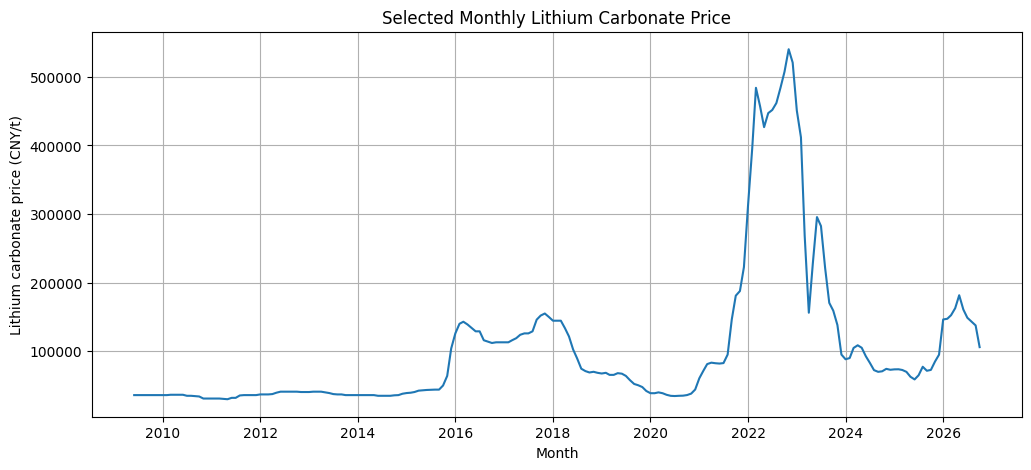

       Selected lithium carbonate price (CNY/t)  \
count                                 89.000000   
mean                              156597.764045   
std                               142779.157315   
min                                34650.000000   
25%                                67250.000000   
50%                                88275.000000   
75%                               181000.000000   
max                               540375.000000   

       Albemarle share price (USD/share)  LME copper price (USD/metric tonne)  \
count                          89.000000                            89.000000   
mean                          144.667447                          8894.437303   
std                            66.550107                          2146.675946   
min                            58.072500                          4993.000000   
25%                            86.534000                          7915.750000   
50%                           126.954000              

In [7]:
plt.figure(figsize=(12, 5))
plt.plot(df['Month'], df[target_col])
plt.xlabel('Month')
plt.ylabel('Lithium carbonate price (CNY/t)')
plt.title('Selected Monthly Lithium Carbonate Price')
plt.grid(True)
plt.show()

print(model_data[feature_cols + ['Next Month Price']].describe())

## 6. Chronological train/test split

The last 20% of observations are held out as the test set. The test period is not used for model selection.

In [8]:
split_index = int(len(model_data) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()
y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()
date_train = dates.iloc[:split_index]
date_test = dates.iloc[split_index:]

print('Training observations:', len(X_train))
print('Testing observations:', len(X_test))
print('Training forecast dates:', date_train.min(), 'to', date_train.max())
print('Testing forecast dates:', date_test.min(), 'to', date_test.max())

Training observations: 71
Testing observations: 18
Training forecast dates: 2019-06-01 00:00:00 to 2025-04-01 00:00:00
Testing forecast dates: 2025-05-01 00:00:00 to 2026-10-01 00:00:00


## 7. Multiple Linear Regression

Start with the simple model, as emphasized in the course. This provides a baseline for judging whether more flexible models improve out-of-sample performance.

In [9]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_train_prediction = linear_model.predict(X_train)
linear_test_prediction = linear_model.predict(X_test)

print('Training R2:', r2_score(y_train, linear_train_prediction))
print('Testing R2:', r2_score(y_test, linear_test_prediction))
print('Testing RMSE:', np.sqrt(mean_squared_error(y_test, linear_test_prediction)))
print('Testing MAE:', mean_absolute_error(y_test, linear_test_prediction))

linear_coefficients = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': linear_model.coef_
})
linear_coefficients

Training R2: 0.959601330052051
Testing R2: 0.6717094184427805
Testing RMSE: 23219.297004914475
Testing MAE: 19260.433549927155


,Feature,Coefficient
0,Selected lithium carbonate price (CNY/t),0.802771
1,Albemarle share price (USD/share),151.425973
2,LME copper price (USD/metric tonne),-0.645471
3,LME cobalt cash price (USD/metric tonne) - upd...,1.880693
4,CNY/USD exchange-rate series (source quote),21778.555168


## 8. K-Nearest Neighbors Regression with GridSearchCV

KNN is sensitive to feature scale, so standardization is included in a pipeline. `TimeSeriesSplit` replaces shuffled / stratified folds because this is a time-series forecasting problem.

In [10]:
time_cv = TimeSeriesSplit(n_splits=3)

knn_pipe = make_pipeline(StandardScaler(), KNeighborsRegressor())
knn_param_grid = {
    'kneighborsregressor__n_neighbors': [3, 5, 7, 9],
    'kneighborsregressor__weights': ['uniform', 'distance']
}

knn_grid = GridSearchCV(
    knn_pipe,
    knn_param_grid,
    cv=time_cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)
knn_grid.fit(X_train, y_train)

print('Best KNN parameters:', knn_grid.best_params_)
print('Best CV RMSE:', np.sqrt(-knn_grid.best_score_))

knn_prediction = knn_grid.predict(X_test)

Best KNN parameters: {'kneighborsregressor__n_neighbors': 3, 'kneighborsregressor__weights': 'distance'}
Best CV RMSE: 151370.53423758235


## 9. Random Forest Regression with GridSearchCV

In [11]:
rf_model = RandomForestRegressor(random_state=42)
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [2, 4, None],
    'min_samples_leaf': [2, 4]
}

rf_grid = GridSearchCV(
    rf_model,
    rf_param_grid,
    cv=time_cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)
rf_grid.fit(X_train, y_train)

print('Best Random Forest parameters:', rf_grid.best_params_)
print('Best CV RMSE:', np.sqrt(-rf_grid.best_score_))

rf_prediction = rf_grid.predict(X_test)

Best Random Forest parameters: {'max_depth': 4, 'min_samples_leaf': 2, 'n_estimators': 200}
Best CV RMSE: 153722.28698902362


## 10. Gradient Boosting Regression with GridSearchCV

In [12]:
gb_model = GradientBoostingRegressor(random_state=42)
gb_param_grid = {
    'n_estimators': [50, 100],
    'learning_rate': [0.03, 0.1],
    'max_depth': [1, 2],
    'min_samples_leaf': [2, 4]
}

gb_grid = GridSearchCV(
    gb_model,
    gb_param_grid,
    cv=time_cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)
gb_grid.fit(X_train, y_train)

print('Best Gradient Boosting parameters:', gb_grid.best_params_)
print('Best CV RMSE:', np.sqrt(-gb_grid.best_score_))

gb_prediction = gb_grid.predict(X_test)

Best Gradient Boosting parameters: {'learning_rate': 0.1, 'max_depth': 1, 'min_samples_leaf': 2, 'n_estimators': 100}
Best CV RMSE: 144840.8522585759


## 11. Gaussian Process Regression: prediction plus uncertainty

A Gaussian Process is especially relevant for a small dataset because it produces both a predictive mean and a predictive standard deviation. Features and target are standardized for numerical stability. The kernel combines a smooth RBF function with a noise term.

In [13]:
x_scaler = StandardScaler()
y_mean = y_train.mean()
y_std = y_train.std()

X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)
y_train_scaled = (y_train - y_mean) / y_std

kernel = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(
    length_scale=1.0, length_scale_bounds=(1e-2, 1e2)
) + WhiteKernel(noise_level=0.1, noise_level_bounds=(1e-5, 1e1))

gpr_model = GaussianProcessRegressor(
    kernel=kernel,
    normalize_y=False,
    n_restarts_optimizer=5,
    random_state=42
)
gpr_model.fit(X_train_scaled, y_train_scaled)

gpr_mean_scaled, gpr_std_scaled = gpr_model.predict(X_test_scaled, return_std=True)

gpr_prediction = gpr_mean_scaled * y_std + y_mean
gpr_std = gpr_std_scaled * y_std

gpr_lower_95 = gpr_prediction - 1.96 * gpr_std
gpr_upper_95 = gpr_prediction + 1.96 * gpr_std

print('Optimized kernel:')
print(gpr_model.kernel_)

Optimized kernel:
0.851**2 * RBF(length_scale=1.06) + WhiteKernel(noise_level=1e-05)


## 12. Compare regression models on the held-out test period

In [14]:
predictions = {
    'Linear Regression': linear_test_prediction,
    'KNN Regression': knn_prediction,
    'Random Forest': rf_prediction,
    'Gradient Boosting': gb_prediction,
    'Gaussian Process': gpr_prediction
}

results = []
for name, prediction in predictions.items():
    results.append({
        'Model': name,
        'RMSE': np.sqrt(mean_squared_error(y_test, prediction)),
        'MAE': mean_absolute_error(y_test, prediction),
        'R2': r2_score(y_test, prediction)
    })

results_df = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)
results_df

,Model,RMSE,MAE,R2
0,Gradient Boosting,13844.441186,11932.901181,0.883289
1,Random Forest,14738.367106,10486.505957,0.867731
2,Gaussian Process,19070.007934,14986.359416,0.778557
3,Linear Regression,23219.297005,19260.433550,0.671709
4,KNN Regression,36643.677036,28875.273461,0.182367


## 13. Actual vs. predicted prices

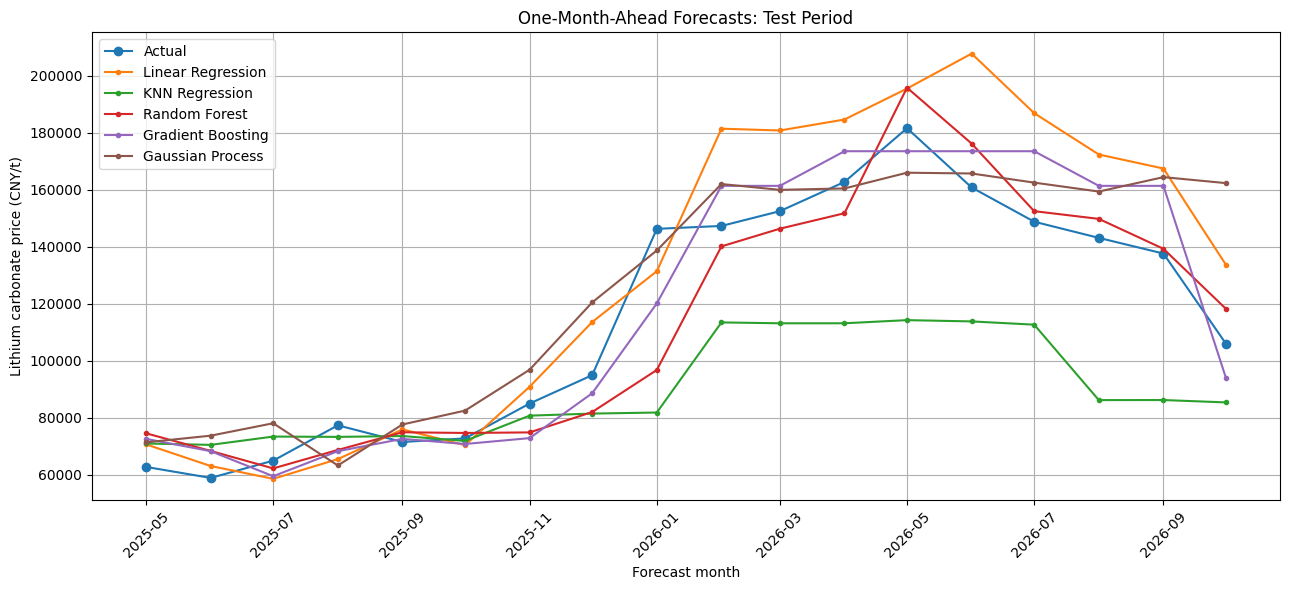

In [15]:
plt.figure(figsize=(13, 6))
plt.plot(date_test, y_test.values, marker='o', label='Actual')
for name, prediction in predictions.items():
    plt.plot(date_test, prediction, marker='.', label=name)
plt.xlabel('Forecast month')
plt.ylabel('Lithium carbonate price (CNY/t)')
plt.title('One-Month-Ahead Forecasts: Test Period')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 14. Gaussian Process uncertainty interval

The shaded region is the GPR's approximate 95% predictive interval (`mean ± 1.96 × standard deviation`). It is a model-based interval, not a guarantee that the true price will fall inside it.

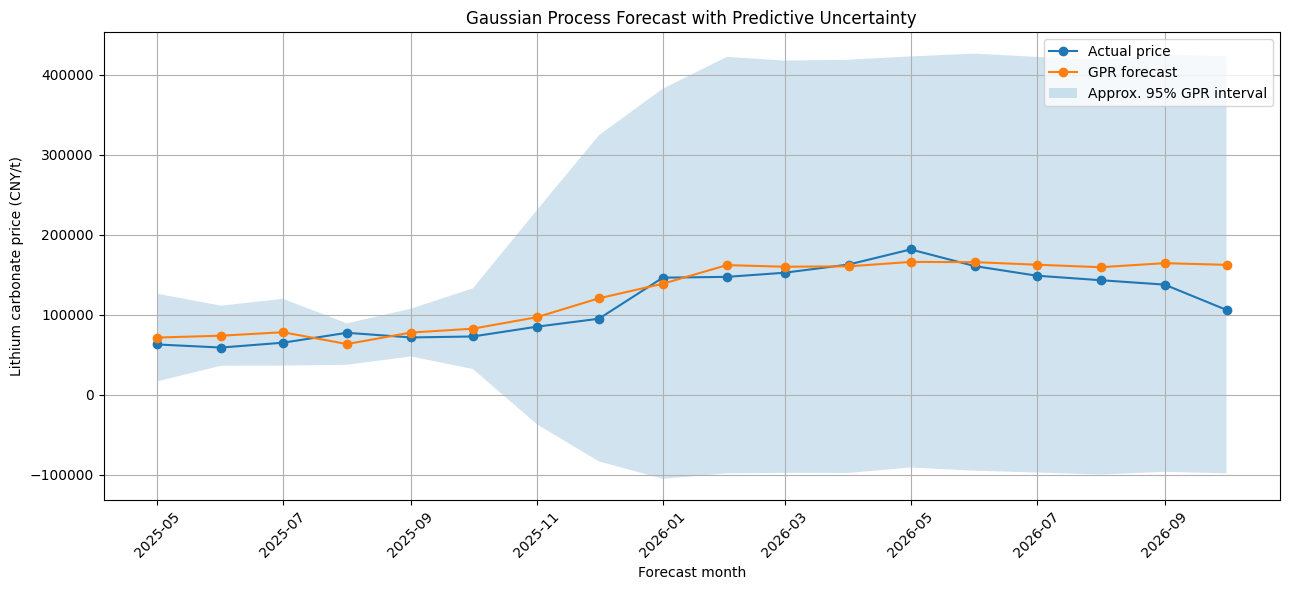

In [16]:
plt.figure(figsize=(13, 6))
plt.plot(date_test, y_test.values, 'o-', label='Actual price')
plt.plot(date_test, gpr_prediction, 'o-', label='GPR forecast')
plt.fill_between(
    date_test,
    gpr_lower_95,
    gpr_upper_95,
    alpha=0.2,
    label='Approx. 95% GPR interval'
)
plt.xlabel('Forecast month')
plt.ylabel('Lithium carbonate price (CNY/t)')
plt.title('Gaussian Process Forecast with Predictive Uncertainty')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 15. Bootstrap / resampling uncertainty check

The GPR interval depends on its kernel assumptions. As a second uncertainty check, we estimate a forecast-error range using rolling-origin predictions within the training period. At each step, the linear regression model is fitted only on earlier observations and predicts the next observation. The empirical 90th percentile of the absolute errors is then used as a simple error band around the selected test forecasts.

This is a practical small-sample resampling-style check; because market errors can be serially correlated and the calibration window is limited, interpret it as an approximate historical error range rather than a formal guarantee.

In [17]:
rolling_errors = []

minimum_history = max(20, int(len(X_train) * 0.40))
for i in range(minimum_history, len(X_train)):
    rolling_model = LinearRegression()
    rolling_model.fit(X_train.iloc[:i], y_train.iloc[:i])
    one_step_prediction = rolling_model.predict(X_train.iloc[[i]])[0]
    rolling_errors.append(y_train.iloc[i] - one_step_prediction)

rolling_errors = np.asarray(rolling_errors)
bootstrap_error_radius = np.quantile(np.abs(rolling_errors), 0.90)

print('Number of rolling-origin calibration errors:', len(rolling_errors))
print('90th percentile absolute forecast error:', round(bootstrap_error_radius, 2), 'CNY/t')

Number of rolling-origin calibration errors: 43
90th percentile absolute forecast error: 72841.3 CNY/t


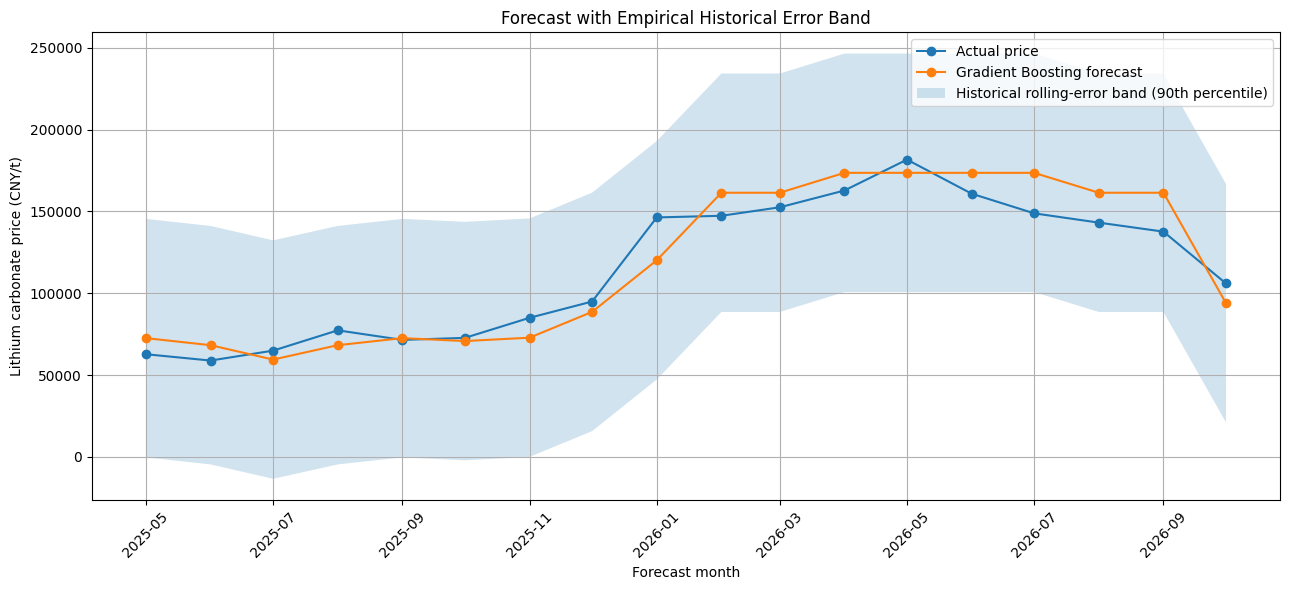

In [18]:
# Apply the empirical error radius to the best-performing test model
best_model_name = results_df.loc[0, 'Model']
best_test_prediction = predictions[best_model_name]

empirical_lower = best_test_prediction - bootstrap_error_radius
empirical_upper = best_test_prediction + bootstrap_error_radius

plt.figure(figsize=(13, 6))
plt.plot(date_test, y_test.values, 'o-', label='Actual price')
plt.plot(date_test, best_test_prediction, 'o-', label=f'{best_model_name} forecast')
plt.fill_between(
    date_test, empirical_lower, empirical_upper,
    alpha=0.2, label='Historical rolling-error band (90th percentile)'
)
plt.xlabel('Forecast month')
plt.ylabel('Lithium carbonate price (CNY/t)')
plt.title('Forecast with Empirical Historical Error Band')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 16. Price-regime classification: low, medium, or high

In addition to predicting a numerical price, we can classify the next month's price into a broad market regime. The cutoffs are the 33rd and 67th percentiles of the **training target only**. This prevents information from the test period from determining the class definitions.

The classification is supplementary: it answers whether the next month is expected to be relatively low, medium, or high compared with the training-period price distribution. It does not replace the numerical forecast.

In [19]:
low_cutoff = y_train.quantile(1/3)
high_cutoff = y_train.quantile(2/3)

def price_regime(values):
    return pd.cut(
        values,
        bins=[-np.inf, low_cutoff, high_cutoff, np.inf],
        labels=['Low', 'Medium', 'High'],
        include_lowest=True
    )

y_train_class = price_regime(y_train)
y_test_class = price_regime(y_test)

print('Low / Medium cutoff:', round(low_cutoff, 2))
print('Medium / High cutoff:', round(high_cutoff, 2))
print('\nTraining class counts:')
print(y_train_class.value_counts())

Low / Medium cutoff: 71977.0
Medium / High cutoff: 158125.0

Training class counts:
Next Month Price
Low       24
High      24
Medium    23
Name: count, dtype: int64


## 17. Logistic Regression classification with GridSearchCV

The classification model uses the same month-*t* predictors to predict the next month's price regime. Features are standardized. The chronological folds are retained.

In [20]:
class_pipe = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=3000, class_weight='balanced')
)

class_param_grid = {
    'logisticregression__C': [0.1, 1, 10]
}

class_grid = GridSearchCV(
    class_pipe,
    class_param_grid,
    cv=time_cv,
    scoring='accuracy',
    n_jobs=-1
)
class_grid.fit(X_train, y_train_class)

class_prediction = class_grid.predict(X_test)

print('Best classification parameters:', class_grid.best_params_)
print('Test accuracy:', accuracy_score(y_test_class, class_prediction))
print(classification_report(y_test_class, class_prediction, zero_division=0))

Best classification parameters: {'logisticregression__C': 0.1}
Test accuracy: 0.6111111111111112
              precision    recall  f1-score   support

        High       0.00      0.00      0.00         3
         Low       0.00      0.00      0.00         4
      Medium       0.61      1.00      0.76        11

    accuracy                           0.61        18
   macro avg       0.20      0.33      0.25        18
weighted avg       0.37      0.61      0.46        18



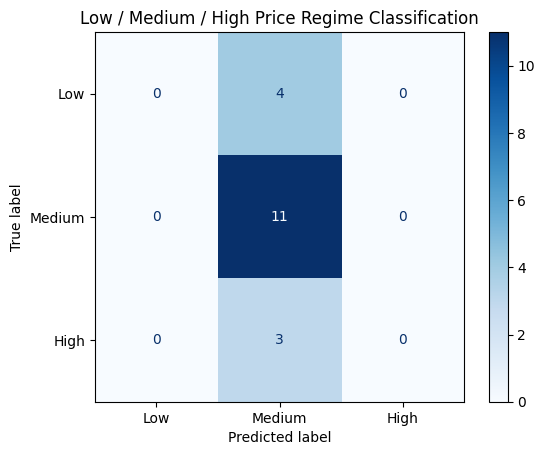

In [21]:
cm = confusion_matrix(
    y_test_class, class_prediction,
    labels=['Low', 'Medium', 'High']
)
display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Low', 'Medium', 'High']
)
display_cm.plot(cmap='Blues')
plt.title('Low / Medium / High Price Regime Classification')
plt.show()

## 18. Random Forest classification comparison

A second classifier provides a non-linear comparison. With a small sample, interpret differences cautiously and do not over-tune the model.

In [22]:
rf_classifier = RandomForestClassifier(
    n_estimators=200,
    max_depth=3,
    min_samples_leaf=3,
    class_weight='balanced',
    random_state=42
)
rf_classifier.fit(X_train, y_train_class)
rf_class_prediction = rf_classifier.predict(X_test)

print('Random Forest classification accuracy:',
      accuracy_score(y_test_class, rf_class_prediction))
print(classification_report(
    y_test_class, rf_class_prediction, zero_division=0
))

Random Forest classification accuracy: 0.7777777777777778
              precision    recall  f1-score   support

        High       1.00      0.67      0.80         3
         Low       0.60      0.75      0.67         4
      Medium       0.82      0.82      0.82        11

    accuracy                           0.78        18
   macro avg       0.81      0.74      0.76        18
weighted avg       0.80      0.78      0.78        18



## 19. Make the next-month forecast

The final row contains the most recent month with a complete set of predictor values. The fitted model forecasts the following month. This cell refits the best-performing regression model on all available supervised observations and also reports a GPR uncertainty interval.

Because the data currently end in October 2026, the forecast month is calculated from the latest available predictor month. The forecast is only as current as the CSV file.

In [23]:
latest_row = df.sort_values('Month').iloc[-1]
latest_month = latest_row['Month']

# Build the latest predictor row in the same feature order used during training
latest_X = pd.DataFrame([{
    col: latest_row[col] for col in feature_cols
}])

if latest_X.isna().any().any():
    print('The latest row does not contain all required predictors.')
else:
    next_month = latest_month + pd.offsets.MonthBegin(1)

    # Refit the selected model on all available supervised data
    if best_model_name == 'Linear Regression':
        final_model = LinearRegression().fit(X, y)
        final_forecast = final_model.predict(latest_X)[0]
    elif best_model_name == 'KNN Regression':
        final_model = knn_grid.best_estimator_
        final_model.fit(X, y)
        final_forecast = final_model.predict(latest_X)[0]
    elif best_model_name == 'Random Forest':
        final_model = rf_grid.best_estimator_
        final_model.fit(X, y)
        final_forecast = final_model.predict(latest_X)[0]
    elif best_model_name == 'Gradient Boosting':
        final_model = gb_grid.best_estimator_
        final_model.fit(X, y)
        final_forecast = final_model.predict(latest_X)[0]
    else:
        # Refit GPR using all observations, then predict the latest month
        final_scaler = StandardScaler()
        X_all_scaled = final_scaler.fit_transform(X)
        X_latest_scaled = final_scaler.transform(latest_X)
        y_all_mean = y.mean()
        y_all_std = y.std()
        y_all_scaled = (y - y_all_mean) / y_all_std

        final_kernel = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(
            length_scale=1.0, length_scale_bounds=(1e-2, 1e2)
        ) + WhiteKernel(noise_level=0.1, noise_level_bounds=(1e-5, 1e1))
        final_gpr = GaussianProcessRegressor(
            kernel=final_kernel, normalize_y=False,
            n_restarts_optimizer=5, random_state=42
        )
        final_gpr.fit(X_all_scaled, y_all_scaled)
        final_mean_scaled, final_std_scaled = final_gpr.predict(
            X_latest_scaled, return_std=True
        )
        final_forecast = final_mean_scaled[0] * y_all_std + y_all_mean
        final_gpr_std = final_std_scaled[0] * y_all_std
        print('GPR approximate 95% interval:',
              round(final_forecast - 1.96 * final_gpr_std, 2), 'to',
              round(final_forecast + 1.96 * final_gpr_std, 2), 'CNY/t')

    print('Latest predictor month:', latest_month.date())
    print('Forecast month:', next_month.date())
    print('Selected regression model:', best_model_name)
    print('Next-month forecast (CNY/t):', round(final_forecast, 2))
    print('Empirical historical error band:',
          round(final_forecast - bootstrap_error_radius, 2), 'to',
          round(final_forecast + bootstrap_error_radius, 2))

Latest predictor month: 2026-10-01
Forecast month: 2026-11-01
Selected regression model: Gradient Boosting
Next-month forecast (CNY/t): 95346.72
Empirical historical error band: 22505.42 to 168188.03


## 20. Classify the forecast month as low, medium, or high

The class cutoffs remain the training-period terciles. The classifier is refitted using all historical supervised observations and the most recent predictor row.

In [24]:
if not latest_X.isna().any().any():
    final_classifier = class_grid.best_estimator_
    final_classifier.fit(X, y_train_class)
    next_regime = final_classifier.predict(latest_X)[0]

    print('Forecast month:', next_month.date())
    print('Predicted price regime:', next_regime)
    print('Low regime: below', round(low_cutoff, 2), 'CNY/t')
    print('Medium regime:', round(low_cutoff, 2), 'to', round(high_cutoff, 2), 'CNY/t')
    print('High regime: above', round(high_cutoff, 2), 'CNY/t')

ValueError: Found input variables with inconsistent numbers of samples: [89, 71]

## 21. Conclusions and limitations

Use the outputs above to complete the interpretation:
1. Which regression model had the lowest held-out RMSE?
2. Did the more flexible models outperform the linear regression baseline?
3. How wide was the GPR predictive interval, and did it widen in less familiar parts of the feature space?
4. Did the empirical rolling-error band tell a similar uncertainty story?
5. How often did the classifier correctly identify low, medium, and high regimes? Which regime was most difficult to classify?

**Limitations to discuss**
- The complete-case dataset is much smaller than the raw 209 monthly rows because several market indicators are only available for part of the period.
- The lithium price series combines source segments. A source transition can create a discontinuity even when overlapping series are highly correlated.
- Some predictors may not be published or observable by the end of month *t*. A production forecasting system should account for publication lags and use only information actually available at the forecast date.
- Monthly observations are serially dependent. A short test period and small training set make model rankings and uncertainty estimates unstable.
- Low / medium / high labels are relative to the training-period price distribution, not fixed economic definitions.
- The GPR interval depends on kernel assumptions, while the empirical error band assumes recent historical errors are informative about future errors.

The forecast should therefore be presented as a model-based estimate with uncertainty, not as a precise prediction of the lithium market.